In [1]:
import gc
import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from IPython.display import display, HTML
from peft import PeftModel
from transformers import AutoModelForImageTextToText, AutoProcessor, BitsAndBytesConfig

BASE_MODEL_DIR = Path("models/Qwen3.5-9B")
ADAPTER_DIR = Path("outputs/qwen35-floorplan-lora/best-checkpoint")

dtype = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else torch.float16

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=dtype,
    bnb_4bit_quant_storage=dtype,
)

processor = AutoProcessor.from_pretrained(ADAPTER_DIR)
if hasattr(processor, "tokenizer"):
    processor.tokenizer.padding_side = "right"

print("Setup ready.")

./.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


Setup ready.


In [2]:
def generate_output(image, question, model, processor, max_new_tokens=300):
    messages = [
        {
            "role": "system",
            "content": [
                {
                    "type": "text",
                    "text": "Return only JSON. No explanation. No reasoning. No extra text.",
                }
            ],
        },
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question},
            ],
        },
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[text],
        images=[[image]],
        return_tensors="pt",
        padding=True,
    )

    device = next(model.parameters()).device
    inputs = {k: v.to(device) if hasattr(v, "to") else v for k, v in inputs.items()}

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=processor.tokenizer.eos_token_id,
        )

    input_len = inputs["input_ids"].shape[1]
    output_text = processor.batch_decode(
        output_ids[:, input_len:],
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()

    return output_text


def compare_generations(base_gen, ft_gen):
    df = pd.DataFrame({
        "Base Model Output": [base_gen],
        "Fine-Tuned Model Output": [ft_gen],
    })

    styled_df = df.style.set_properties(**{
        "text-align": "left",
        "white-space": "pre-wrap",
        "border": "1px solid black",
        "padding": "10px",
        "width": "420px",
        "overflow-wrap": "break-word",
    })

    display(HTML(styled_df.to_html()))


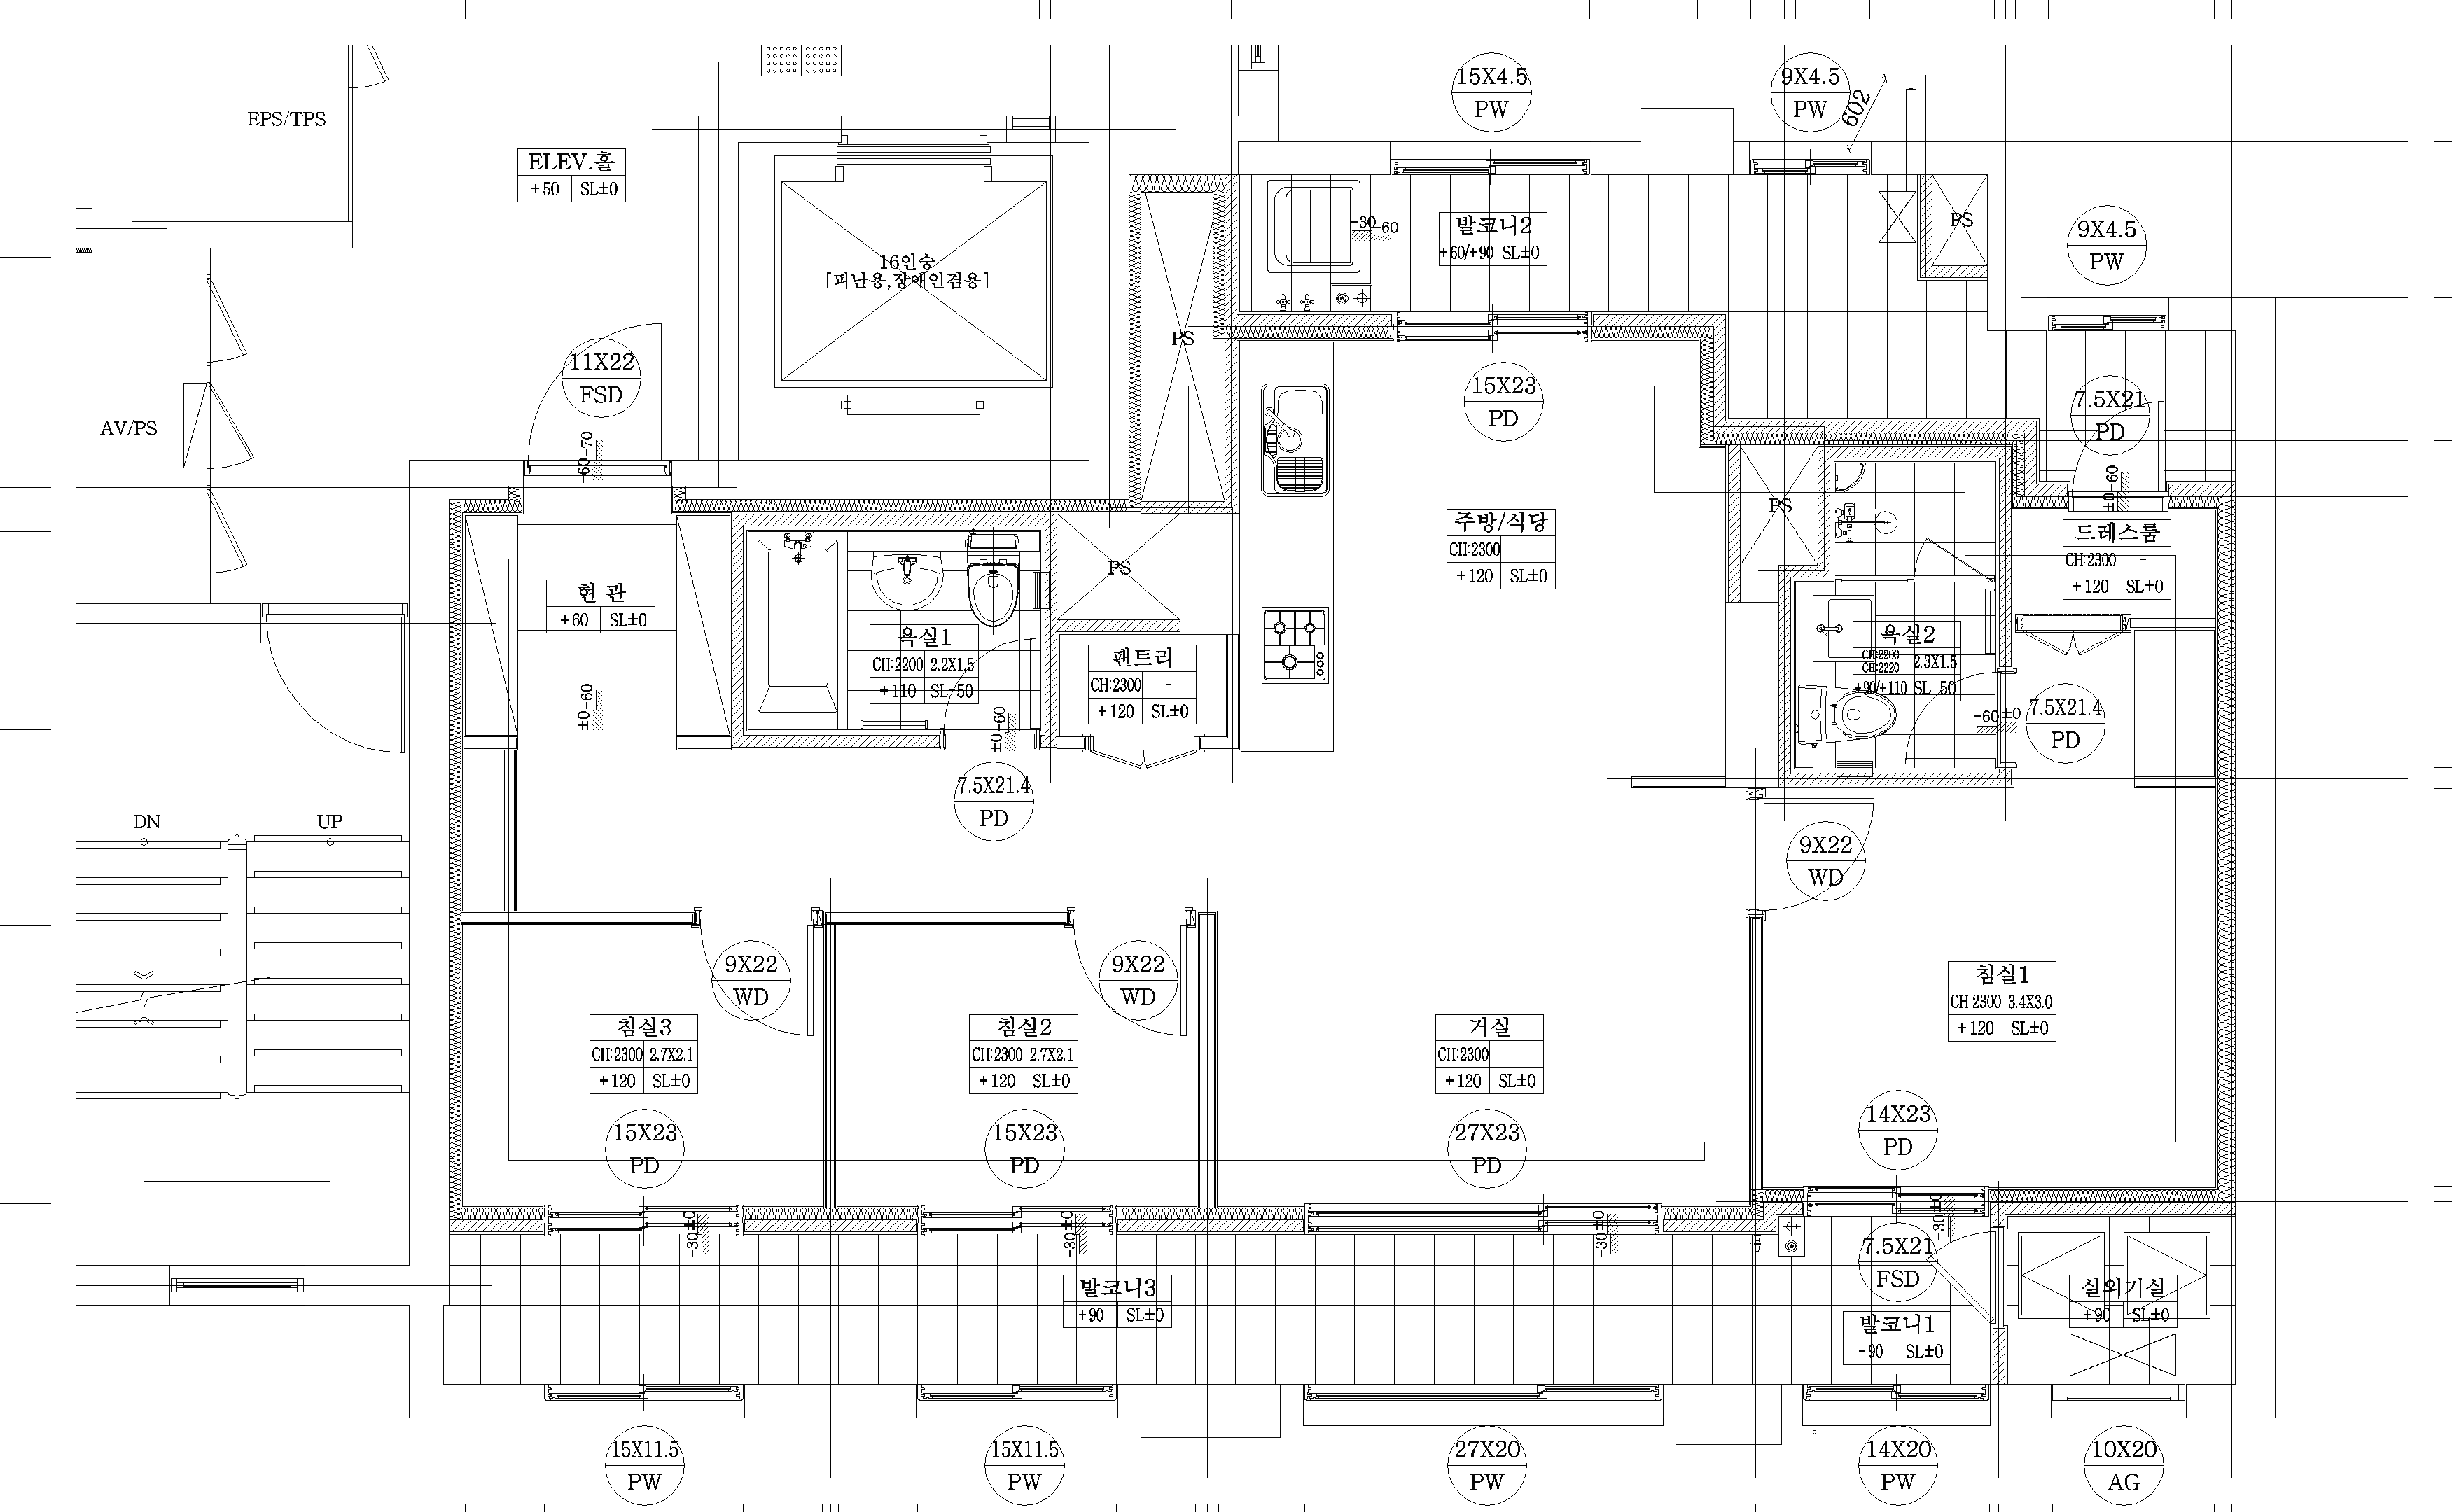

Question: analyze the door in this floor plan: tell me whether it is present, how many instances exist, and return all polygons if present


In [3]:
image_path = "raw_data/images/00005.png"
image = Image.open(image_path).convert("RGB")

question = "analyze the door in this floor plan: tell me whether it is present, how many instances exist, and return all polygons if present"

display(image)
print("Question:", question)


In [4]:
print("Loading base model...")

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

base_model = AutoModelForImageTextToText.from_pretrained(
    BASE_MODEL_DIR,
    torch_dtype=dtype,
    quantization_config=bnb_config,
)

base_model = base_model.to(DEVICE)
base_model.eval()

base_output = generate_output(image, question, base_model, processor)
print("Base model done.")
print(base_output)

`torch_dtype` is deprecated! Use `dtype` instead!


Loading base model...


The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d
Loading weights: 100%|██████████| 760/760 [00:05<00:00, 136.08it/s]


Base model done.
The user wants me to identify doors in the provided floor plan.

1.  **Analyze the image:** I see a floor plan with various rooms labeled in Korean.
    *   Top left: Elevator shaft (ELEV. 홀).
    *   Top middle: A large room labeled "16인승" (16-seater), likely a meeting room or similar.
    *   Top right: Balcony 2 (발코니2).
    *   Middle left: Bathroom 1 (욕실1), Pantry (팬트리), Hallway (현관).
    *   Middle right: Kitchen/Dining (주방/식당), Bathroom 2 (욕실2), Dressing room (드레스룸).
    *   Bottom left: Bedroom 3 (침실3), Bedroom 2 (침실2).
    *   Bottom middle: Living room (거실), Balcony 3 (발코니3).
    *   Bottom right: Bedroom 1 (침실1), Balcony 1 (발코니1), Utility room (실외기실).

2.  **Identify doors:** I need to look for standard door symbols. These are usually represented by a line with a swing arc or a line with a specific door symbol (like a rectangle with a line indicating the swing).
    *   **Door 1:** Near the entrance


In [6]:
del base_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Base model cleared from memory.")


Base model cleared from memory.


In [7]:
print("Loading fine-tuned model...")
ft_base_model = AutoModelForImageTextToText.from_pretrained(
    BASE_MODEL_DIR,
    torch_dtype=dtype,
    quantization_config=bnb_config,
    device_map="auto",
)
ft_model = PeftModel.from_pretrained(ft_base_model, ADAPTER_DIR)
ft_model.eval()

ft_output = generate_output(image, question, ft_model, processor)
print("Fine-tuned model done.")
print(ft_output)


Loading fine-tuned model...


Loading weights: 100%|██████████| 760/760 [00:03<00:00, 250.81it/s]


Fine-tuned model done.
Based on the visual analysis of the floor plan:

1.  **Identify the class:** The user is asking for "Junction type I", which corresponds to L-junctions.
2.  **Scan the image:** I will look for corners where two walls meet at a 90-degree angle.
3.  **Count and record polygons:**
    *   **Living Kitchen (Left side):**
        *   Top-left corner: [100.0, 336.0], [144.0, 336.0], [144.0, 360.0], [100.0, 360.0]
        *   Top-right corner (near stairs): [335.0, 336.0], [359.0, 336.0], [359.0, 360.0], [335.0, 360.0]
        *   Top-right corner (near stairs - other side): [335.0, 459.0], [359.0, 459.0], [359.0, 483.0], [335.0, 483.0]
        *   Top-right corner (near stairs - other side


In [8]:
compare_generations(base_output, ft_output)

,Base Model Output,Fine-Tuned Model Output
0,"The user wants me to analyze ""Junction type I"" in the provided floor plan. 1. **Identify ""Junction type I"":** In architectural floor plans, junctions are typically where walls meet. * **Type I (T-junction):** A wall ends at another wall (perpendicular or parallel). This is the most common type. It looks like a 'T'. * **Type II (L-junction):** Two walls meet at a 90-degree angle. * **Type III (Cross-junction):** Two walls cross each other (though less common in simple wall layouts, usually implies a specific structural element or just a cross). * **Type IV (Corner/End):** A wall ends at the end of another wall (perpendicular). Wait, let's look at standard architectural notation for junctions. * **Junction Type I:** Usually refers to a T-junction where a wall terminates into another wall. * **Junction Type II:** Usually refers to an L-junction (corner). * **Junction Type III:** Usually refers to a cross-junction (X). * **Junction Type IV:** Usually refers to a corner where a wall ends at the end of another wall (perpendicular). Let's re-evaluate based on the visual evidence. * Looking at the walls in the","Based on the visual analysis of the floor plan: 1. **Identify the class:** The user is asking for ""Junction type I"", which corresponds to L-junctions. 2. **Scan the image:** I will look for corners where two walls meet at a 90-degree angle. 3. **Count and record polygons:** * **Living Kitchen (Left side):** * Top-left corner: [100.0, 336.0], [144.0, 336.0], [144.0, 360.0], [100.0, 360.0] * Top-right corner (near stairs): [335.0, 336.0], [359.0, 336.0], [359.0, 360.0], [335.0, 360.0] * Top-right corner (near stairs - other side): [335.0, 459.0], [359.0, 459.0], [359.0, 483.0], [335.0, 483.0] * Top-right corner (near stairs - other side"
